Loaded 263 spatial zones.
Shapefile Columns: ['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough', 'geometry']


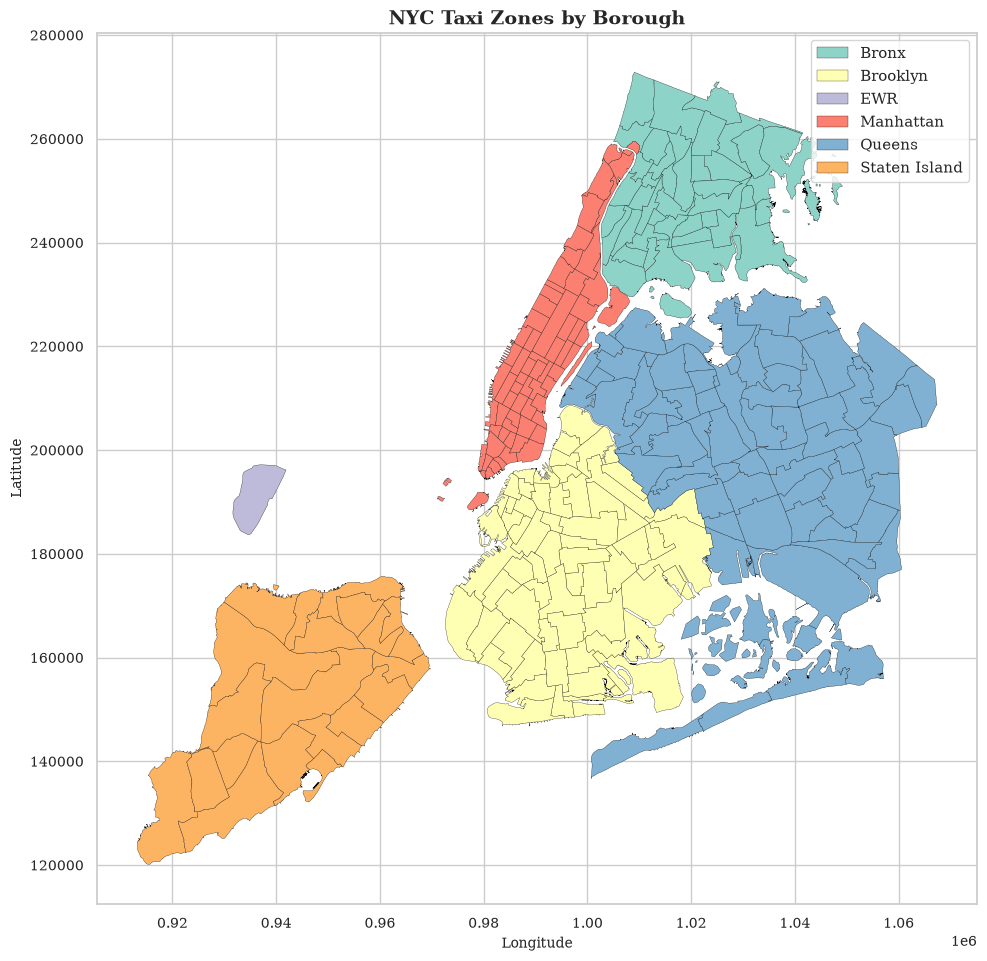

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Load the spatial polygons from the ESRI shapefile bundle
# Ensure all files (shp, shx, dbf, prj) are in your '../data/spatial/' directory
shapefile_path = '../data/spatial/taxi_zones.shp'
gdf_zones = gpd.read_file(shapefile_path)

print(f"Loaded {len(gdf_zones)} spatial zones.")
print("Shapefile Columns:", gdf_zones.columns.tolist())

# 2. (Optional) Load the taxi zone lookup CSV to merge descriptive metadata (Borough, Zone names)
import pandas as pd
df_lookup = pd.read_csv('../data/spatial/taxi_zone_lookup.csv')

# Merge shapefile with lookup table on LocationID
# Note: The shapefile usually stores the ID under 'LocationID' or 'OBJECTID'
if 'LocationID' in gdf_zones.columns:
    gdf_merged = gdf_zones.merge(df_lookup, on='LocationID', how='left')
else:
    # Fallback if the shapefile column is named 'OBJECTID'
    gdf_merged = gdf_zones.merge(df_lookup, left_on='OBJECTID', right_on='LocationID', how='left')

# 3. Plot the spatial polygons
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

# Plot polygons colored by Borough (or just plain if borough isn't merged)
if 'Borough' in gdf_merged.columns:
    gdf_merged.plot(
        column='Borough', 
        ax=ax, 
        legend=True, 
        edgecolor='black', 
        linewidth=0.2, 
        cmap='Set3',
        missing_kwds={'color': 'lightgrey'}
    )
    plt.title('NYC Taxi Zones by Borough', fontsize=14, fontweight='bold')
else:
    gdf_merged.plot(ax=ax, color='lightblue', edgecolor='black', linewidth=0.2)
    plt.title('NYC Taxi Zone Polygons', fontsize=14, fontweight='bold')

plt.xlabel('Longitude', fontsize=10)
plt.ylabel('Latitude', fontsize=10)
plt.tight_layout()
plt.show()